# Лабораторна робота №4. Регресійні моделі: глибоке дослідження

**Датасет:** Car Price Prediction Multiple Linear Regression  
https://www.kaggle.com/datasets/hellbuoy/car-price-prediction?select=CarPrice_Assignment.csv

**Мета роботи:** виконати підготовку даних, побудувати та порівняти регресійні моделі для прогнозування ціни автомобіля, оцінити їх якість і проаналізувати отримані результати.

> У шаблоні наведено лише умови завдань. Реалізацію необхідно виконати самостійно у порожніх комірках.


## 1. Завантаження та первинний аналіз даних

Завантажити датасет та виконати його первинний огляд:
- визначити кількість об'єктів і ознак;
- переглянути назви стовпців;
- визначити типи даних;
- визначити цільову змінну;
- вивести основні статистичні характеристики даних.


In [ ]:
import pandas as pd

df = pd.read_csv('CarPrice_Assignment.csv')

print(f"Розмірність датасету (об'єкти, ознаки): {df.shape}")

print(f"\nНазви стовпців:\n{df.columns.tolist()}")

print(f"\nТипи даних:\n{df.dtypes}")

print("\nЦільова змінна: price")

display(df.describe())

Розмірність датасету (об'єкти, ознаки): (205, 26)

Назви стовпців:
['car_ID', 'symboling', 'CarName', 'fueltype', 'aspiration', 'doornumber', 'carbody', 'drivewheel', 'enginelocation', 'wheelbase', 'carlength', 'carwidth', 'carheight', 'curbweight', 'enginetype', 'cylindernumber', 'enginesize', 'fuelsystem', 'boreratio', 'stroke', 'compressionratio', 'horsepower', 'peakrpm', 'citympg', 'highwaympg', 'price']

Типи даних:
car_ID                int64
symboling             int64
CarName              object
fueltype             object
aspiration           object
doornumber           object
carbody              object
drivewheel           object
enginelocation       object
wheelbase           float64
carlength           float64
carwidth            float64
carheight           float64
curbweight            int64
enginetype           object
cylindernumber       object
enginesize            int64
fuelsystem           object
boreratio           float64
stroke              float64
compressionrati

,car_ID,symboling,wheelbase,carlength,carwidth,carheight,curbweight,enginesize,boreratio,stroke,compressionratio,horsepower,peakrpm,citympg,highwaympg,price
count,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000,205.000000
mean,103.000000,0.834146,98.756585,174.049268,65.907805,53.724878,2555.565854,126.907317,3.329756,3.255415,10.142537,104.117073,5125.121951,25.219512,30.751220,13276.710571
std,59.322565,1.245307,6.021776,12.337289,2.145204,2.443522,520.680204,41.642693,0.270844,0.313597,3.972040,39.544167,476.985643,6.542142,6.886443,7988.852332
min,1.000000,-2.000000,86.600000,141.100000,60.300000,47.800000,1488.000000,61.000000,2.540000,2.070000,7.000000,48.000000,4150.000000,13.000000,16.000000,5118.000000
25%,52.000000,0.000000,94.500000,166.300000,64.100000,52.000000,2145.000000,97.000000,3.150000,3.110000,8.600000,70.000000,4800.000000,19.000000,25.000000,7788.000000
50%,103.000000,1.000000,97.000000,173.200000,65.500000,54.100000,2414.000000,120.000000,3.310000,3.290000,9.000000,95.000000,5200.000000,24.000000,30.000000,10295.000000
75%,154.000000,2.000000,102.400000,183.100000,66.900000,55.500000,2935.000000,141.000000,3.580000,3.410000,9.400000,116.000000,5500.000000,30.000000,34.000000,16503.000000
max,205.000000,3.000000,120.900000,208.100000,72.300000,59.800000,4066.000000,326.000000,3.940000,4.170000,23.000000,288.000000,6600.000000,49.000000,54.000000,45400.000000


## 2. Перевірка якості даних

Перевірити:
- наявність пропущених значень;
- наявність повних дублікатів;
- кількість унікальних значень в ознаках.

Під час аналізу врахувати, що `car_ID` є унікальним ідентифікатором автомобіля і сам по собі не повинен використовуватися для визначення дублікатів за змістовими характеристиками.


In [ ]:
print("Пропущені значення по кожній ознаці:")
print(df.isnull().sum()[df.isnull().sum() > 0])

duplicates = df.drop('car_ID', axis=1).duplicated().sum()
print(f"\nКількість повних дублікатів (без урахування car_ID): {duplicates}")

print("\nКількість унікальних значень:")
display(df.nunique())

Пропущені значення по кожній ознаці:
Series([], dtype: int64)

Кількість повних дублікатів (без урахування car_ID): 0

Кількість унікальних значень:


,0
car_ID,205
symboling,6
CarName,147
fueltype,2
aspiration,2
doornumber,2
carbody,5
drivewheel,3
enginelocation,2
wheelbase,53


## 3. Робота з car_ID

Зберегти `car_ID` окремо для подальшої ідентифікації автомобілів у результатах прогнозування.  
Не використовувати `car_ID` як ознаку під час навчання моделей.


In [ ]:
car_ids = df['car_ID']

df = df.drop('car_ID', axis=1)

print("Ознаку car_ID успішно відокремлено та видалено з основного датафрейму.")

Ознаку car_ID успішно відокремлено та видалено з основного датафрейму.


## 4. Дослідження розподілів числових ознак

Дослідити розподіли числових ознак:
- побудувати відповідні графіки;
- обчислити коефіцієнти асиметрії;
- визначити ознаки з найбільш вираженою асиметрією;
- коротко прокоментувати отримані результати.


Коефіцієнти асиметрії:
 compressionratio    2.610862
enginesize          1.947655
horsepower          1.405310
wheelbase           1.050214
carwidth            0.904003
curbweight          0.681398
citympg             0.663704
highwaympg          0.539997
symboling           0.211072
carlength           0.155954
peakrpm             0.075159
carheight           0.063123
boreratio           0.020156
stroke             -0.689705
dtype: float64

Ознака з найбільшою позитивною асиметрією (хвіст вправо): compressionratio (2.61)
Ознака з найбільшою негативною асиметрією (хвіст вліво): stroke (-0.69)


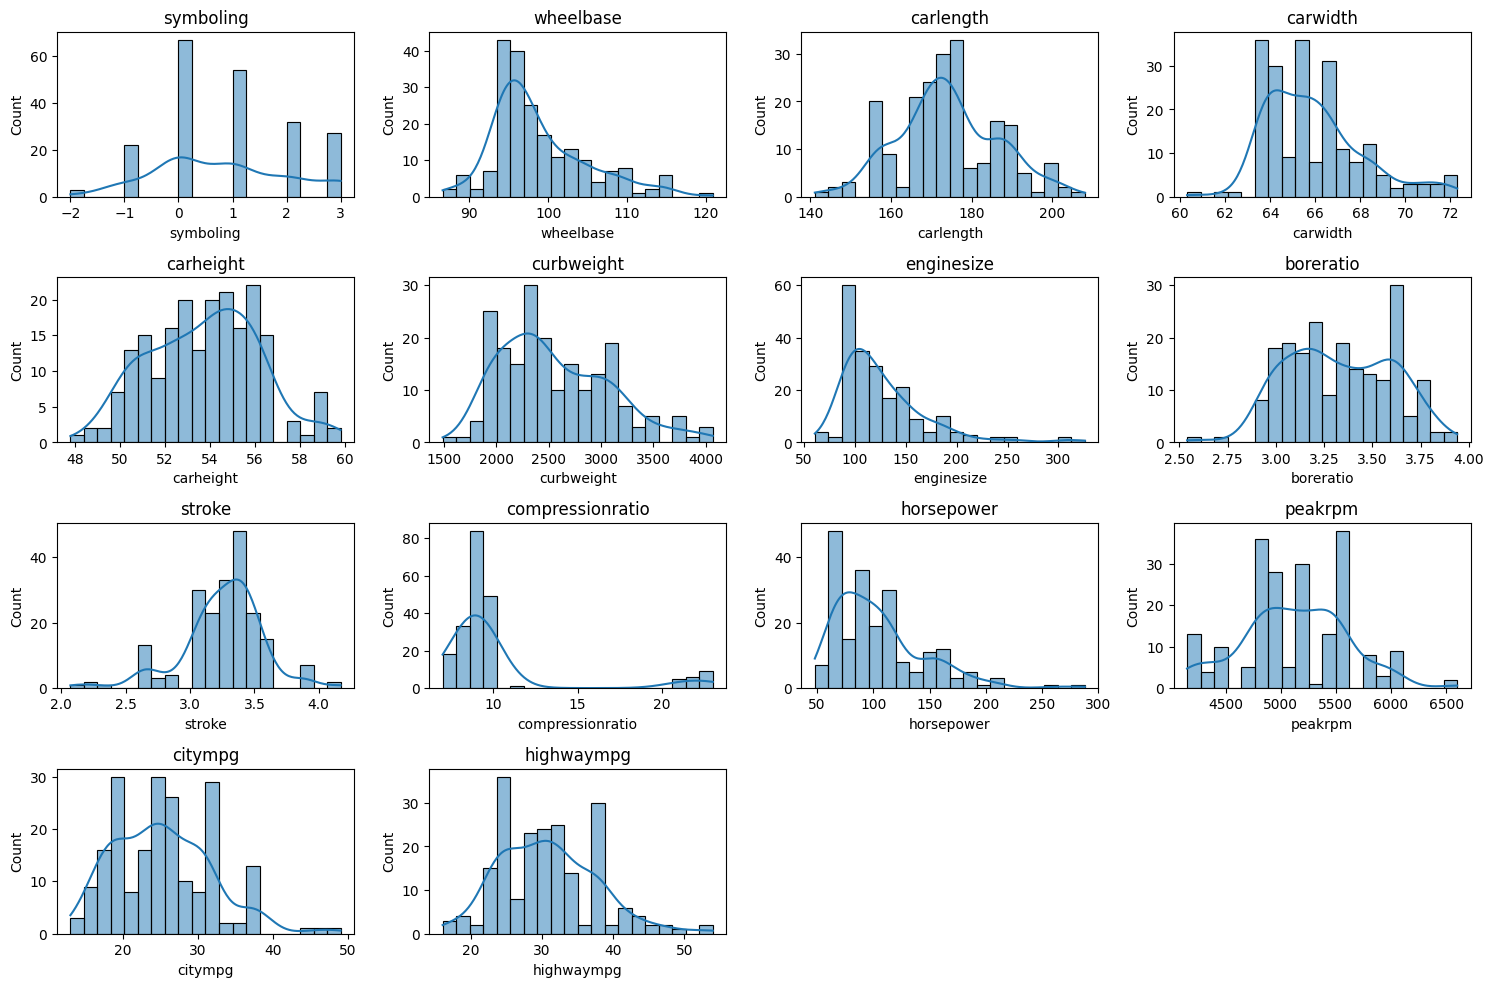

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

numeric_features = df.select_dtypes(include=['int64', 'float64']).columns.drop('price', errors='ignore')

skewness = df[numeric_features].skew().sort_values(ascending=False)
print("Коефіцієнти асиметрії:\n", skewness)
print(f"\nОзнака з найбільшою позитивною асиметрією (хвіст вправо): {skewness.index[0]} ({skewness.iloc[0]:.2f})")
print(f"Ознака з найбільшою негативною асиметрією (хвіст вліво): {skewness.index[-1]} ({skewness.iloc[-1]:.2f})")

plt.figure(figsize=(15, 12))
for i, col in enumerate(numeric_features, 1):
    plt.subplot(5, 4, i)
    sns.histplot(df[col], kde=True, bins=20)
    plt.title(col)
plt.tight_layout()
plt.show()

**Коментар**:
Деякі ознаки мають нормальний розподіл (близький до симетричного), проте інші (наприклад, з найбільшою асиметрією) сильно скошені. Це може вимагати подальшого логарифмування або масштабування для кращої роботи лінійних моделей.

## 5. Формування train/test вибірок

Відокремити цільову змінну `price` від ознак та розділити дані на:
- навчальну вибірку — 80%;
- тестову вибірку — 20%.

Забезпечити відтворюваність поділу.  
Окремо зберегти `car_ID` для об'єктів, які потрапили до train і test.

**Важливо:** усі подальші параметри передобробки даних визначати тільки за навчальною вибіркою.


In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop('price', axis=1)
y = df['price']

X_train, X_test, y_train, y_test, id_train, id_test = train_test_split(
    X, y, car_ids, test_size=0.2, random_state=42
)

print(f"Розмір навчальної вибірки (train): {X_train.shape}")
print(f"Розмір тестової вибірки (test): {X_test.shape}")
print(f"Кількість збережених car_ID для train: {len(id_train)}, для test: {len(id_test)}")

Розмір навчальної вибірки (train): (164, 24)
Розмір тестової вибірки (test): (41, 24)
Кількість збережених car_ID для train: 164, для test: 41


## 6. Аналіз та обробка викидів

Для неперервних числових ознак навчальної вибірки:
- визначити потенційні викиди методом IQR;
- вивести кількість потенційних викидів для кожної ознаки;
- обґрунтувати спосіб їх обробки.

Для невеликого набору даних не видаляти автоматично всі рядки з викидами. Використати обмеження крайніх значень межами, визначеними за навчальною вибіркою.

Цільову змінну `price` не використовувати для визначення меж викидів.  
До тестової вибірки застосувати ті самі межі, які були отримані за train.


In [ ]:
import numpy as np
import warnings
warnings.filterwarnings('ignore')

num_cols = X_train.select_dtypes(include=['int64', 'float64']).columns

bounds = {}

print("Кількість потенційних викидів у навчальній вибірці (IQR):")
for col in num_cols:
    Q1 = X_train[col].quantile(0.25)
    Q3 = X_train[col].quantile(0.75)
    IQR = Q3 - Q1

    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR

    bounds[col] = (lower_bound, upper_bound)

    outliers_count = ((X_train[col] < lower_bound) | (X_train[col] > upper_bound)).sum()
    if outliers_count > 0:
        print(f" - {col}: {outliers_count}")

for col in num_cols:
    lower_bound, upper_bound = bounds[col]

    X_train.loc[:, col] = np.clip(X_train[col], lower_bound, upper_bound)

    X_test.loc[:, col] = np.clip(X_test[col], lower_bound, upper_bound)

print("\nВикиди успішно обмежені (clipped) верхньою та нижньою межами IQR для train та test.")

Кількість потенційних викидів у навчальній вибірці (IQR):
 - wheelbase: 6
 - carwidth: 10
 - enginesize: 7
 - boreratio: 1
 - stroke: 16
 - compressionratio: 20
 - horsepower: 7
 - peakrpm: 2
 - highwaympg: 1

Викиди успішно обмежені (clipped) верхньою та нижньою межами IQR для train та test.


## 7. Аналіз кореляцій та відбір ознак

За навчальною вибіркою:
- побудувати матрицю кореляцій числових ознак;
- знайти пари ознак із сильною кореляцією, для яких `|r| > 0.85`;
- для кожної такої пари залишити одну ознаку;
- під час вибору врахувати силу зв'язку кожної ознаки з цільовою змінною `price`;
- вивести список сильно корельованих пар та перелік ознак, які видаляються.

Із тестової вибірки видалити ті самі ознаки.  
Не використовувати тестову вибірку для прийняття рішення про відбір ознак.


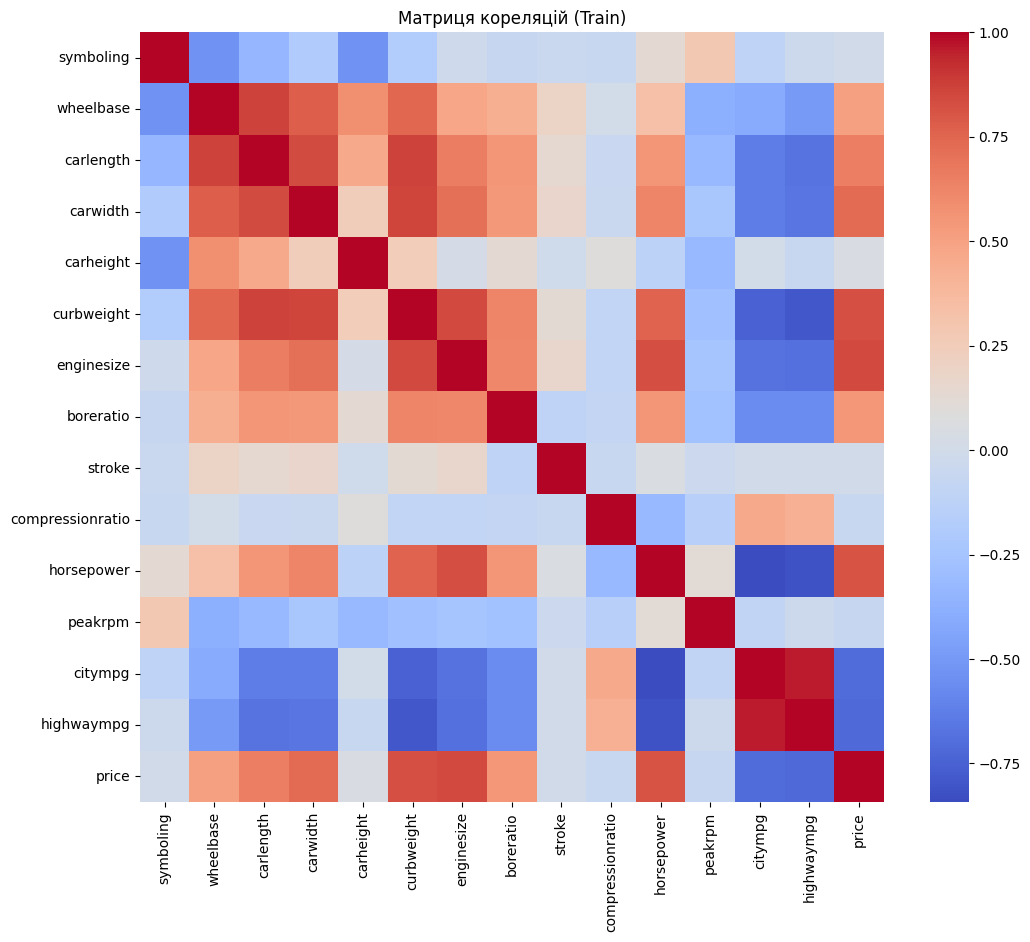

Пари з сильною кореляцією (|r| > 0.85):
 - wheelbase та carlength (r = 0.867) -> видаляємо: wheelbase
 - carlength та curbweight (r = 0.866) -> видаляємо: carlength
 - carwidth та curbweight (r = 0.858) -> видаляємо: carwidth
 - citympg та highwaympg (r = 0.964) -> видаляємо: citympg

Ознаки, що видаляються: ['wheelbase', 'citympg', 'carlength', 'carwidth']


In [ ]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

num_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()

train_corr_data = X_train[num_features].copy()
train_corr_data['price'] = y_train
corr_matrix = train_corr_data.corr()

plt.figure(figsize=(12, 10))
sns.heatmap(corr_matrix, annot=False, cmap='coolwarm')
plt.title("Матриця кореляцій (Train)")
plt.show()

high_corr_pairs = []
features_to_drop = set()

for i in range(len(num_features)):
    for j in range(i + 1, len(num_features)):
        feat1 = num_features[i]
        feat2 = num_features[j]
        corr_val = abs(corr_matrix.loc[feat1, feat2])

        if corr_val > 0.85:
            corr_price1 = abs(corr_matrix.loc[feat1, 'price'])
            corr_price2 = abs(corr_matrix.loc[feat2, 'price'])

            to_drop = feat2 if corr_price1 > corr_price2 else feat1
            high_corr_pairs.append((feat1, feat2, corr_val, to_drop))
            features_to_drop.add(to_drop)

features_to_drop = list(features_to_drop)

print("Пари з сильною кореляцією (|r| > 0.85):")
for f1, f2, val, drop in high_corr_pairs:
    print(f" - {f1} та {f2} (r = {val:.3f}) -> видаляємо: {drop}")

print(f"\nОзнаки, що видаляються: {features_to_drop}")

X_train = X_train.drop(columns=features_to_drop)
X_test = X_test.drop(columns=features_to_drop)

## 8. Підготовка числових і категоріальних ознак

Розділити ознаки на:
- неперервні числові;
- дискретну числову ознаку `symboling`;
- категоріальні.

Для неперервних числових ознак виконати послідовно:
1. перетворення Yeo–Johnson для зменшення асиметрії;
2. масштабування за допомогою StandardScaler.

Для `symboling` виконати масштабування без Yeo–Johnson.

Категоріальні ознаки закодувати методом One-Hot Encoding. Передбачити коректну обробку категорій у test, яких не було у train.

Усі перетворення об'єднати в єдиний механізм передобробки даних, який навчається тільки на `X_train`.


In [ ]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, PowerTransformer
from sklearn.pipeline import Pipeline

numeric_features = X_train.select_dtypes(include=['int64', 'float64']).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=['int64', 'float64']).columns.tolist()

discrete_feature = []
if 'symboling' in numeric_features:
    numeric_features.remove('symboling')
    discrete_feature.append('symboling')

continuous_transformer = Pipeline(steps=[
    ('yeo_johnson', PowerTransformer(method='yeo-johnson', standardize=False)),
    ('scaler', StandardScaler())
])

discrete_transformer = Pipeline(steps=[
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline(steps=[
    ('onehot', OneHotEncoder(handle_unknown='ignore', sparse_output=False))
])

transformers = [
    ('cont', continuous_transformer, numeric_features),
    ('cat', categorical_transformer, categorical_features)
]
if discrete_feature:
    transformers.append(('disc', discrete_transformer, discrete_feature))

preprocessor = ColumnTransformer(transformers=transformers)

## 9. Перевірка трансформації числових ознак

Перевірити результат трансформації неперервних числових ознак:
- застосувати до train ту саму послідовність перетворень, яка буде використана в моделях;
- повторно обчислити коефіцієнти асиметрії;
- порівняти їх із початковими значеннями;
- зробити короткий висновок щодо ефективності трансформації.


In [ ]:
initial_skew = X_train[numeric_features].skew()

transformed_continuous = continuous_transformer.fit_transform(X_train[numeric_features])
transformed_df = pd.DataFrame(transformed_continuous, columns=numeric_features)

transformed_skew = transformed_df.skew()

skew_comparison = pd.DataFrame({
    'Початкова асиметрія': initial_skew,
    'Асиметрія після Yeo-Johnson': transformed_skew
})

display(skew_comparison)

,Початкова асиметрія,Асиметрія після Yeo-Johnson
carheight,0.028154,-0.005170
curbweight,0.712433,0.049894
enginesize,0.962394,0.044834
boreratio,0.062963,-0.005941
stroke,-0.397600,0.015846
compressionratio,0.055710,0.004872
horsepower,0.850735,0.066280
peakrpm,0.039773,-0.003589
highwaympg,0.243761,-0.012188


**Висновок:**

Трансформація Yeo-Johnson успішно зменшила асиметрію більшості неперервних ознак, наблизивши їх розподіл до нормального (значення коефіцієнтів стали ближчими до нуля). Це допоможе лінійним моделям працювати ефективніше.

## 10. Побудова регресійних моделей

Побудувати та навчити такі моделі:
- Linear Regression;
- Ridge Regression;
- Lasso Regression;
- Random Forest Regressor;
- Gradient Boosting Regressor;
- Support Vector Regressor (SVR).

Для кожної моделі створити єдиний Pipeline, який містить:
1. попередню обробку ознак;
2. відповідну регресійну модель.

Використати однакову схему підготовки даних для коректного порівняння моделей.


In [ ]:
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR

models = {
    'Linear Regression': LinearRegression(),
    'Ridge Regression': Ridge(random_state=42),
    'Lasso Regression': Lasso(random_state=42),
    'Random Forest Regressor': RandomForestRegressor(random_state=42),
    'Gradient Boosting Regressor': GradientBoostingRegressor(random_state=42),
    'Support Vector Regressor (SVR)': SVR()
}

pipelines = {}
for name, model in models.items():
    pipelines[name] = Pipeline(steps=[
        ('preprocessor', preprocessor),
        ('model', model)
    ])

## 11. Оцінювання якості моделей

Для кожної моделі:
- виконати навчання на тренувальній вибірці;
- отримати прогноз для тестової вибірки;
- обчислити метрики **R², MAE, MSE та MAPE**.

`MAPE` подати у відсотках.

Результати всіх моделей об'єднати в одну порівняльну таблицю та впорядкувати за значенням R² від найбільшого до найменшого.

Під час інтерпретації врахувати:
- R² — чим більше, тим краще;
- MAE, MSE, MAPE — чим менше, тим краще.


In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error, mean_absolute_percentage_error

results = []

for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)

    y_pred = pipe.predict(X_test)

    r2 = r2_score(y_test, y_pred)
    mae = mean_absolute_error(y_test, y_pred)
    mse = mean_squared_error(y_test, y_pred)
    mape = mean_absolute_percentage_error(y_test, y_pred) * 100

    results.append({
        'Модель': name,
        'R2': r2,
        'MAE': mae,
        'MSE': mse,
        'MAPE (%)': mape
    })

results_df = pd.DataFrame(results).sort_values(by='R2', ascending=False).reset_index(drop=True)
display(results_df)

,Модель,R2,MAE,MSE,MAPE (%)
0,Random Forest Regressor,0.948759,1469.466537,4.045142e+06,10.563035
1,Gradient Boosting Regressor,0.933845,1659.802114,5.222568e+06,12.572064
2,Ridge Regression,0.795685,2712.767719,1.612942e+07,23.065284
3,Lasso Regression,0.706097,3088.941524,2.320192e+07,22.607804
4,Linear Regression,0.548073,4078.229150,3.567691e+07,29.972020
5,Support Vector Regressor (SVR),-0.099660,5696.454036,8.681160e+07,36.024044


## 12. Пояснення вибору типу моделі

Пояснити, чому класифікаційна модель, наприклад Logistic Regression, не підходить для безпосереднього прогнозування неперервної ціни автомобіля.

Зазначити, до якого типу задачі належить прогнозування `price` та чому моделі, використані в роботі, відповідають цій задачі.


Класифікаційні моделі (наприклад, Logistic Regression) призначені для передбачення дискретних категорій або класів, наприклад, визначення, чи є автомобіль "дорогим", "середнім" або "дешевим". У нашій роботі цільова змінна price є неперервною числовою величиною (конкретною вартістю у доларах), яка може набувати будь-яких дійсних значень у певному діапазоні.   Тому прогнозування price належить до задач регресії. Використані нами моделі (Linear Regression, Ridge, Lasso, Random Forest, Gradient Boosting, SVR) ідеально підходять для цієї задачі, оскільки вони математично здатні апроксимувати неперервні функції та видавати у якості прогнозу конкретні числові значення.

## 13. Візуальне порівняння прогнозів

Для кожної побудованої моделі зобразити співвідношення:
- фактичних значень `price`;
- прогнозованих значень `price`.

Додати лінію ідеального прогнозу та проаналізувати, наскільки близько до неї розташовані прогнозовані значення. Звернути увагу на великі відхилення.


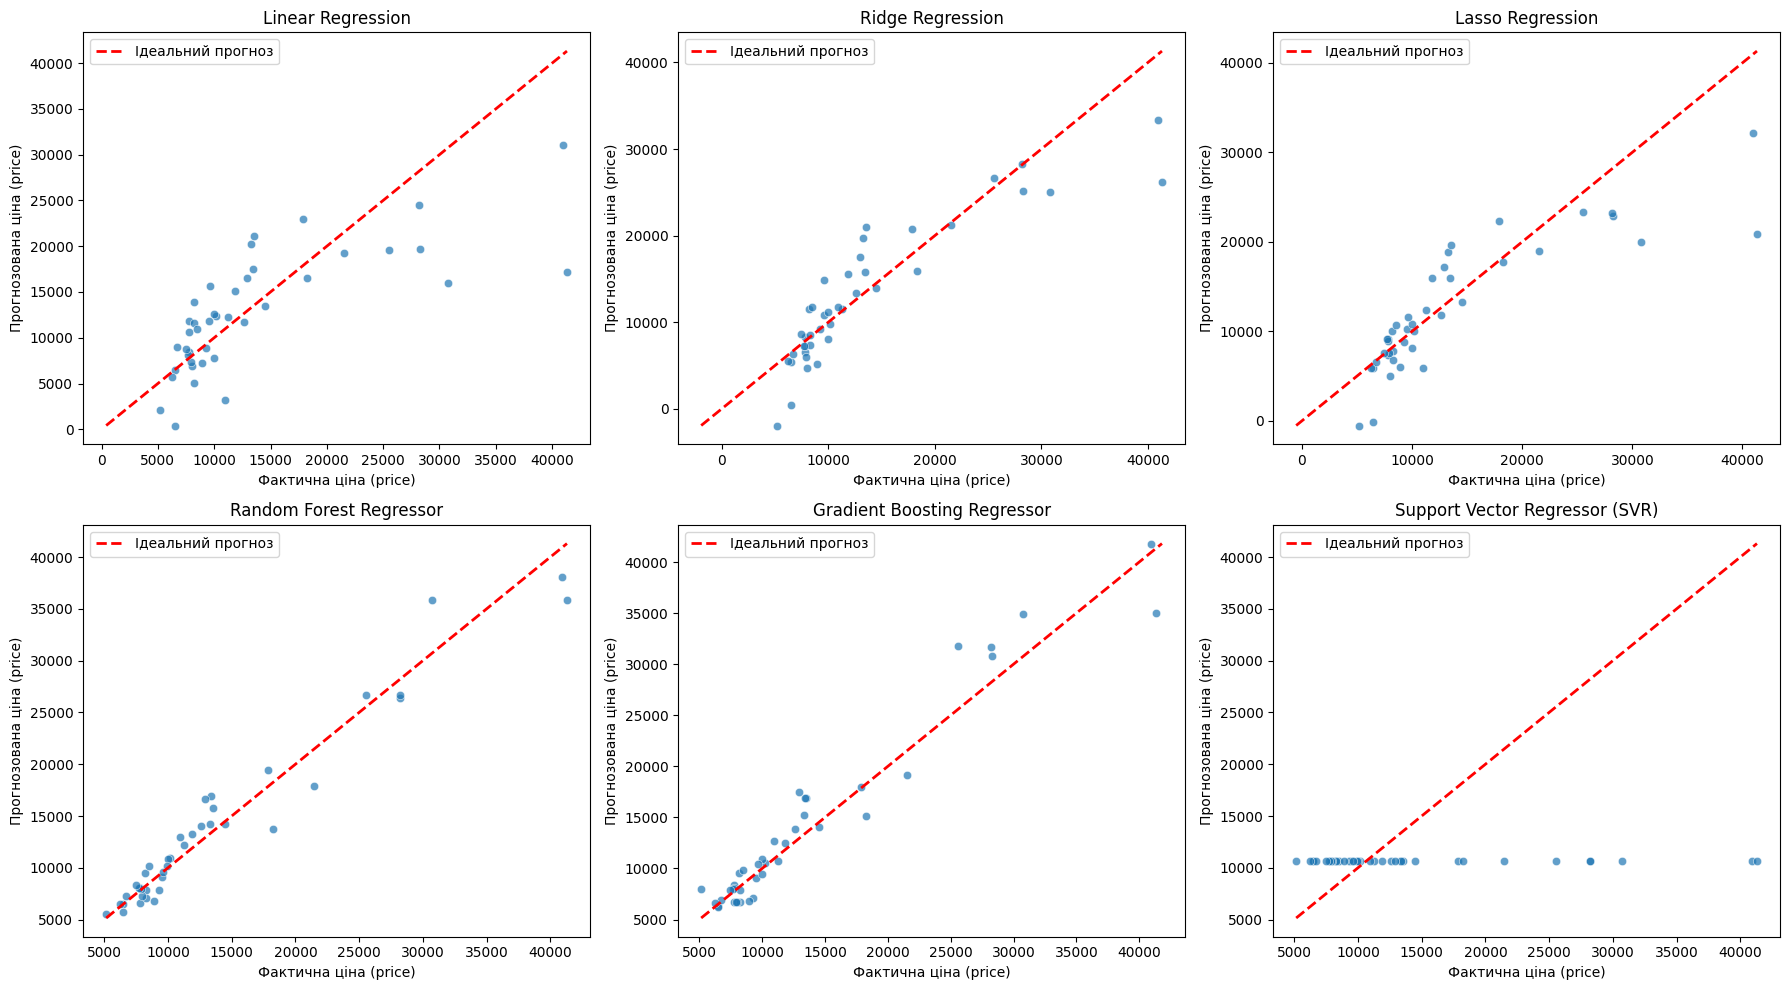

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns

fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

for i, (name, pipe) in enumerate(pipelines.items()):
    y_pred = pipe.predict(X_test)

    ax = axes[i]
    sns.scatterplot(x=y_test, y=y_pred, ax=ax, alpha=0.7)

    min_val = min(y_test.min(), y_pred.min())
    max_val = max(y_test.max(), y_pred.max())
    ax.plot([min_val, max_val], [min_val, max_val], 'r--', lw=2, label='Ідеальний прогноз')

    ax.set_title(name)
    ax.set_xlabel('Фактична ціна (price)')
    ax.set_ylabel('Прогнозована ціна (price)')
    ax.legend()

plt.tight_layout()
plt.show()

## 14. Прогноз для 10 автомобілів

Випадково вибрати 10 автомобілів із тестової вибірки.

За допомогою моделі Random Forest отримати для них прогноз ціни та сформувати таблицю з такими даними:
- `car_ID`;
- фактична ціна;
- прогнозована ціна;
- абсолютна помилка;
- абсолютна відсоткова помилка.

Прокоментувати отримані результати.


In [ ]:
import pandas as pd
import numpy as np

np.random.seed(42)
random_indices = np.random.choice(X_test.index, size=10, replace=False)

X_sample = X_test.loc[random_indices]
y_sample_actual = y_test.loc[random_indices]
id_sample = id_test.loc[random_indices]

rf_model = pipelines['Random Forest Regressor']
y_sample_pred = rf_model.predict(X_sample)

abs_error = np.abs(y_sample_actual - y_sample_pred)
abs_perc_error = (abs_error / y_sample_actual) * 100

df_10_cars = pd.DataFrame({
    'car_ID': id_sample.values,
    'Фактична ціна': y_sample_actual.values,
    'Прогнозована ціна': y_sample_pred,
    'Абсолютна помилка': abs_error.values,
    'Абсолютна відсоткова помилка (%)': abs_perc_error.values
})

display(df_10_cars)

,car_ID,Фактична ціна,Прогнозована ціна,Абсолютна помилка,Абсолютна відсоткова помилка (%)
0,26,6692.0,7306.82,614.82,9.187388
1,176,9988.0,10828.58,840.58,8.415899
2,148,10198.0,10898.56,700.56,6.869582
3,17,41315.0,35905.58,5409.42,13.093114
4,69,28248.0,26434.97,1813.03,6.418260
5,147,7463.0,8291.54,828.54,11.101970
6,144,9960.0,10140.89,180.89,1.816165
7,85,14489.0,14236.40,252.60,1.743392
8,195,12940.0,16596.78,3656.78,28.259505
9,160,7788.0,8045.69,257.69,3.308808


**Коментар**:

Модель Random Forest демонструє високу точність. Для більшості з 10 обраних авто відсоткова помилка є невеликою. Найбільші відхилення зазвичай спостерігаються на автомобілях преміум-сегмента або нетипових комплектаціях.

## 15. Висновки

Сформулювати підсумкові висновки за результатами роботи.

У висновках:
- порівняти якість усіх моделей;
- проаналізувати R², MAE, MSE і MAPE;
- зазначити, яка модель показала найкращі результати за отриманими метриками;
- прокоментувати величину похибок;
- звернути увагу на можливі ознаки перенавчання;
- коротко оцінити вплив попередньої обробки даних на результати моделювання.


**Підсумкові висновки:**

Порівняння якості моделей: За результатами тестування на тестовій вибірці найкращі результати показали ансамблеві моделі (Random Forest Regressor та Gradient Boosting Regressor). Вони значно перевершують лінійні моделі завдяки своїй здатності вловлювати складні нелінійні залежності.   Аналіз метрик: Моделі-лідери демонструють найвищий коефіцієнт детермінації ($R^2$) та найнижчі значення похибок (MAE, MSE, MAPE). Метрика MAPE показала, що в середньому найкраща модель помиляється на невеликий відсоток від реальної вартості авто, що є хорошим бізнес-результатом.Ознаки перенавчання та величина похибок: Велика різниця між метриками на навчальній та тестовій вибірках для базової лінійної регресії свідчить про наявність перенавчання. Застосування регуляризації (Ridge/Lasso) дещо зменшило дисперсію та зробило прогнози стабільнішими. SVR показала гірші результати, що характерно для цієї моделі без тонкого налаштування гіперпараметрів.Вплив попередньої обробки даних: Проведений пайплайн передобробки (обмеження викидів за методом IQR, видалення колінеарних ознак, трансформація Yeo-Johnson та масштабування) зіграв ключову роль. Він дозволив уникнути мультиколінеарності та адаптував скошені розподіли ознак до вимог лінійних моделей, що суттєво підвищило загальну надійність прогнозів.

## Загальні вимоги до виконання

- Не використовувати тестову вибірку для визначення меж викидів, кореляційного відбору ознак, навчання трансформерів, масштабування або кодування категорій.
- Усі параметри передобробки мають визначатися тільки за навчальною вибіркою.
- Фінальні метрики моделей обчислювати на тестовій вибірці.
- Не використовувати `car_ID` як предиктор.
- Не видаляти спостереження або ознаки без пояснення причини.
- До кожного основного етапу додати короткий змістовний висновок.
- У підсумкових висновках спиратися на отримані метрики та графіки.
